In [1]:
# import boston housing data
from keras.datasets import california_housing
(x_train, y_train), (x_test, y_test) = california_housing.load_data()
print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)

743530/743530 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(16512, 8)
(16512,)
(4128, 8)
(4128,)


In [8]:
from keras.models import Sequential
from keras.layers import Dense, BatchNormalization

# Creating Sequential Model
model = Sequential()

# Input layer with Batch Normalization added separately
model.add(Dense(8, activation='relu', input_shape=(8,)))
model.add(BatchNormalization())

# Hidden layers
model.add(Dense(25, activation='relu'))

model.add(Dense(25, activation='relu'))

# Output layer
model.add(Dense(1))

# Model summary
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 8)              │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8)              │            32 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 25)             │           225 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 25)             │           650 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,005 (3.93 KB)

 Trainable params: 989 (3.86 KB)

 Non-trainable params: 16 (64.00 B)

In [9]:
# Let us compile the model
model.compile(optimizer='adam',
              loss='mse',
              metrics=['mae'])



In [10]:
# Let us fit the model
price = model.fit(x_train,
                  y_train,
                  epochs=15,
                  batch_size=20,
                  verbose=1)

Epoch 1/15
826/826 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 52877328384.0000 - mae: 199483.1250
Epoch 2/15
826/826 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 21679114240.0000 - mae: 115919.2344
Epoch 3/15
826/826 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 10939443200.0000 - mae: 82894.5703
Epoch 4/15
826/826 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 9000418304.0000 - mae: 74721.8203
Epoch 5/15
826/826 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 7641218560.0000 - mae: 67835.4062
Epoch 6/15
826/826 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 6625667584.0000 - mae: 62410.5273
Epoch 7/15
826/826 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 5980019200.0000 - mae: 58374.9961
Epoch 8/15
826/826 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 5834948608.0000 - mae: 57388.6172
Epoch 9/15
826/826 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 5624229376.0000 - mae: 56088.5742
Epoch 10/15
826/826 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 5524576256.0000 - mae: 55611.7148
Epoch 11/15
826/826 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step -

In [11]:
model.evaluate(x_test,y_test)

129/129 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 5093707264.0000 - mae: 52118.0039


[5093707264.0, 52118.00390625]

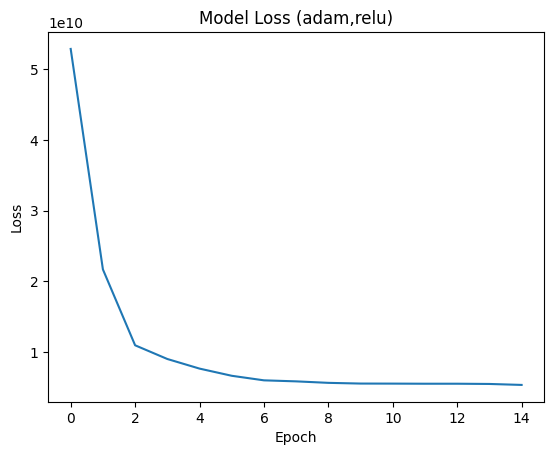

In [12]:
# Let us visualize
import matplotlib.pyplot as plt

plt.plot(price.history['loss'])
plt.title('Model Loss (adam,relu)')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.show()